# Urban tree survival prediction

US cities invest heavily in urban tree planting, but many trees die
prematurely due to poor species-site matching. We build a binary
classifier that predicts whether a tree will survive at a given urban
location based on species, site characteristics, climate, and soil
properties. This can help municipalities select the right species for
each site and cut replanting costs.

Dataset: ~1M urban tree records from 15 US states with species info,
location, climate, and soil features at three soil depths.
Target: `survival_label` (1 = alive, 0 = dead/dying).

## 1. Setup and imports

We suppress sklearn/xgboost warnings to keep output clean.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

SAMPLE_MODE = True

if SAMPLE_MODE:
    MAX_TRAIN_ROWS = 200_000
    RF_ESTIMATORS = 100
    XGB_ESTIMATORS = 100
    KNN_NEIGHBORS = 10
    KNN_MAX_SAMPLES = 30_000
    print('SAMPLE MODE: ON')
else:
    MAX_TRAIN_ROWS = None
    RF_ESTIMATORS = 300
    XGB_ESTIMATORS = 300
    KNN_NEIGHBORS = 15
    KNN_MAX_SAMPLES = 100_000
    print('FULL MODE: ON')

SAMPLE MODE: ON


## 2. Data loading
The default is `data/sample_plants.csv` for exploration. For full dataset experiments, set `PLANTS_DATA_PATH`. Plots below were saved from the original larger experiment and may not match sample reruns.


In [3]:
from pathlib import Path
import os

# By default, use the small example dataset included in this repository.
# For the original full dataset, set PLANTS_DATA_PATH to its local file path.
DATA_PATH = Path(os.environ.get("PLANTS_DATA_PATH", "data/sample_plants.csv"))
if not DATA_PATH.exists() and not os.environ.get("PLANTS_DATA_PATH"):
    DATA_PATH = Path("../data/sample_plants.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Missing dataset: {DATA_PATH.resolve()}")
df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows from {DATA_PATH}")
df.shape


(1013701, 62)

In [ ]:
# Google Drive mount is not needed for local use.


In [4]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].replace({'': np.nan, '<null>': np.nan})

print(f'Shape: {df.shape}')
print(f'\nColumn types:')
print(df.dtypes.value_counts())
print(f'\nMissing values (top 15):')
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False).head(15))
df.head()

Shape: (1013701, 62)

Column types:
float64    49
object     12
int64       1
Name: count, dtype: int64

Missing values (top 15):
height_M                            991379
height_binned_M                     974160
overhead_utility                    930701
diameter_breast_height_CM           451987
location_type                       424244
Family                              255353
native                              237434
themes                              106851
diameter_breast_height_binned_CM     72819
sci_name_clean                       41171
common_name                           6705
city                                   461
dtype: int64


,common_name,sci_name_clean,Family,city,state,location_type,overhead_utility,diameter_breast_height_CM,diameter_breast_height_binned_CM,height_M,...,soil_nitrogen_15_30,soil_ocd_15_30,soil_phh2o_15_30,soil_sand_15_30,soil_silt_15_30,soil_soc_15_30,soil_wv0010_15_30,soil_wv0033_15_30,soil_wv1500_15_30,themes
0,Live oak,quercus virginiana,Fagaceae,Plano,Texas,NaN,NaN,54.61,45.72 to 60.96 cm,NaN,...,1.06,19.4,7.1,31.1,29.2,12.7,33.2,27.8,17.5,"['Butterfly Garden', 'Native Garden', 'Nightti..."
1,Live oak,quercus virginiana,Fagaceae,Plano,Texas,NaN,NaN,30.48,15.24 to 30.48 cm,NaN,...,1.06,19.4,7.1,31.1,29.2,12.7,33.2,27.8,17.5,"['Butterfly Garden', 'Native Garden', 'Nightti..."
2,Live oak,quercus virginiana,Fagaceae,Plano,Texas,NaN,NaN,29.21,15.24 to 30.48 cm,NaN,...,1.06,19.4,7.1,31.1,29.2,12.7,33.2,27.8,17.5,"['Butterfly Garden', 'Native Garden', 'Nightti..."
3,Live oak,quercus virginiana,Fagaceae,Plano,Texas,NaN,NaN,22.86,15.24 to 30.48 cm,NaN,...,1.06,19.4,7.1,31.1,29.2,12.7,33.2,27.8,17.5,"['Butterfly Garden', 'Native Garden', 'Nightti..."
4,Live oak,quercus virginiana,Fagaceae,Plano,Texas,NaN,NaN,22.86,15.24 to 30.48 cm,NaN,...,1.06,19.4,7.1,31.1,29.2,12.7,33.2,27.8,17.5,"['Butterfly Garden', 'Native Garden', 'Nightti..."


## 3. Exploratory data analysis

### 3.1 Target variable and condition

We look at the target distribution and how it relates to the
`condition` column.

In [5]:
df.columns

Index(['common_name', 'sci_name_clean', 'Family', 'city', 'state',
       'location_type', 'overhead_utility', 'diameter_breast_height_CM',
       'diameter_breast_height_binned_CM', 'height_M', 'height_binned_M',
       'native', 'condition', 'survival_label', 'temp_max_avg', 'temp_min_avg',
       'temp_min_extreme', 'precip_annual_avg', 'frost_days_avg',
       'evapotransp_avg', 'soil_moisture_avg', 'soil_temp_avg',
       'soil_bdod_0_5', 'soil_cec_0_5', 'soil_cfvo_0_5', 'soil_clay_0_5',
       'soil_nitrogen_0_5', 'soil_ocd_0_5', 'soil_phh2o_0_5', 'soil_sand_0_5',
       'soil_silt_0_5', 'soil_soc_0_5', 'soil_wv0010_0_5', 'soil_wv0033_0_5',
       'soil_wv1500_0_5', 'soil_bdod_5_15', 'soil_cec_5_15', 'soil_cfvo_5_15',
       'soil_clay_5_15', 'soil_nitrogen_5_15', 'soil_ocd_5_15',
       'soil_phh2o_5_15', 'soil_sand_5_15', 'soil_silt_5_15', 'soil_soc_5_15',
       'soil_wv0010_5_15', 'soil_wv0033_5_15', 'soil_wv1500_5_15',
       'soil_bdod_15_30', 'soil_cec_15_30', 'soil_cfvo_1

In [6]:
import numpy as np
import pandas as pd
risk = (df['survival_label'] == 0) | df['condition'].isin(['poor', 'dead', 'dead/dying'])

df['survival_label'] = np.where(risk, 0, 1).astype(int)

df['survival_label'].value_counts().sort_index()
bad_cols = ['condition', 'city', 'survival_label']
X = df.drop(columns=bad_cols).select_dtypes('number')
y = df['survival_label']

X.columns

Index(['diameter_breast_height_CM', 'height_M', 'temp_max_avg', 'temp_min_avg',
       'temp_min_extreme', 'precip_annual_avg', 'frost_days_avg',
       'evapotransp_avg', 'soil_moisture_avg', 'soil_temp_avg',
       'soil_bdod_0_5', 'soil_cec_0_5', 'soil_cfvo_0_5', 'soil_clay_0_5',
       'soil_nitrogen_0_5', 'soil_ocd_0_5', 'soil_phh2o_0_5', 'soil_sand_0_5',
       'soil_silt_0_5', 'soil_soc_0_5', 'soil_wv0010_0_5', 'soil_wv0033_0_5',
       'soil_wv1500_0_5', 'soil_bdod_5_15', 'soil_cec_5_15', 'soil_cfvo_5_15',
       'soil_clay_5_15', 'soil_nitrogen_5_15', 'soil_ocd_5_15',
       'soil_phh2o_5_15', 'soil_sand_5_15', 'soil_silt_5_15', 'soil_soc_5_15',
       'soil_wv0010_5_15', 'soil_wv0033_5_15', 'soil_wv1500_5_15',
       'soil_bdod_15_30', 'soil_cec_15_30', 'soil_cfvo_15_30',
       'soil_clay_15_30', 'soil_nitrogen_15_30', 'soil_ocd_15_30',
       'soil_phh2o_15_30', 'soil_sand_15_30', 'soil_silt_15_30',
       'soil_soc_15_30', 'soil_wv0010_15_30', 'soil_wv0033_15_30',
       '

In [7]:
df.columns

Index(['common_name', 'sci_name_clean', 'Family', 'city', 'state',
       'location_type', 'overhead_utility', 'diameter_breast_height_CM',
       'diameter_breast_height_binned_CM', 'height_M', 'height_binned_M',
       'native', 'condition', 'survival_label', 'temp_max_avg', 'temp_min_avg',
       'temp_min_extreme', 'precip_annual_avg', 'frost_days_avg',
       'evapotransp_avg', 'soil_moisture_avg', 'soil_temp_avg',
       'soil_bdod_0_5', 'soil_cec_0_5', 'soil_cfvo_0_5', 'soil_clay_0_5',
       'soil_nitrogen_0_5', 'soil_ocd_0_5', 'soil_phh2o_0_5', 'soil_sand_0_5',
       'soil_silt_0_5', 'soil_soc_0_5', 'soil_wv0010_0_5', 'soil_wv0033_0_5',
       'soil_wv1500_0_5', 'soil_bdod_5_15', 'soil_cec_5_15', 'soil_cfvo_5_15',
       'soil_clay_5_15', 'soil_nitrogen_5_15', 'soil_ocd_5_15',
       'soil_phh2o_5_15', 'soil_sand_5_15', 'soil_silt_5_15', 'soil_soc_5_15',
       'soil_wv0010_5_15', 'soil_wv0033_5_15', 'soil_wv1500_5_15',
       'soil_bdod_15_30', 'soil_cec_15_30', 'soil_cfvo_1

In [8]:
len(['state','location_type', 'overhead_utility'])

3

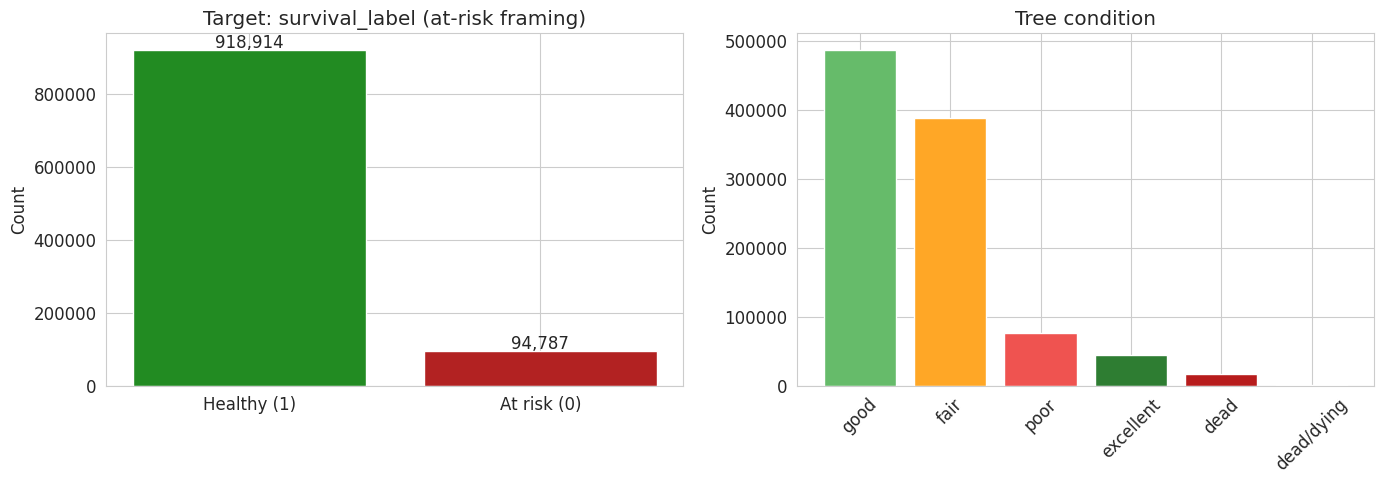

Class imbalance ratio: 9.7:1 (healthy:at_risk)
At-risk (poor+dead+dying): 94787 == survival_label=0: 94787


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = df['survival_label'].value_counts()
axes[0].bar(['Healthy (1)', 'At risk (0)'], [counts[1], counts[0]],
            color=['forestgreen', 'firebrick'])
axes[0].set_title('Target: survival_label (at-risk framing)')
axes[0].set_ylabel('Count')
for i, v in enumerate([counts[1], counts[0]]):
    axes[0].text(i, v + 5000, f'{v:,}', ha='center')

cond_counts = df['condition'].value_counts()
cond_colors = {'excellent': '#2e7d32', 'good': '#66bb6a', 'fair': '#ffa726',
               'poor': '#ef5350', 'dead': '#b71c1c', 'dead/dying': '#880e4f'}
axes[1].bar(cond_counts.index, cond_counts.values,
            color=[cond_colors.get(c, 'gray') for c in cond_counts.index])
axes[1].set_title('Tree condition')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(f'Class imbalance ratio: {counts[1] / counts[0]:.1f}:1 (healthy:at_risk)')
at_risk_count = df[df["condition"].isin(["poor", "dead", "dead/dying"])].shape[0]
print(f'At-risk (poor+dead+dying): {at_risk_count} == survival_label=0: {counts[0]}')

The `condition` column maps directly to the target: "dead" and
"dead/dying" correspond exactly to `survival_label=0`. Using it as a
feature would be data leakage, so we drop it before modeling.

The target is heavily imbalanced - about 55:1 ratio of alive to dead
trees. We will use class weights and appropriate metrics (AUC-ROC, F1)
rather than accuracy.

### 3.2 Categorical features

We check the distribution of species, family, state, and location
type.

unique species: 1933
unique families: 88
unique cities: 79
unique states: 15


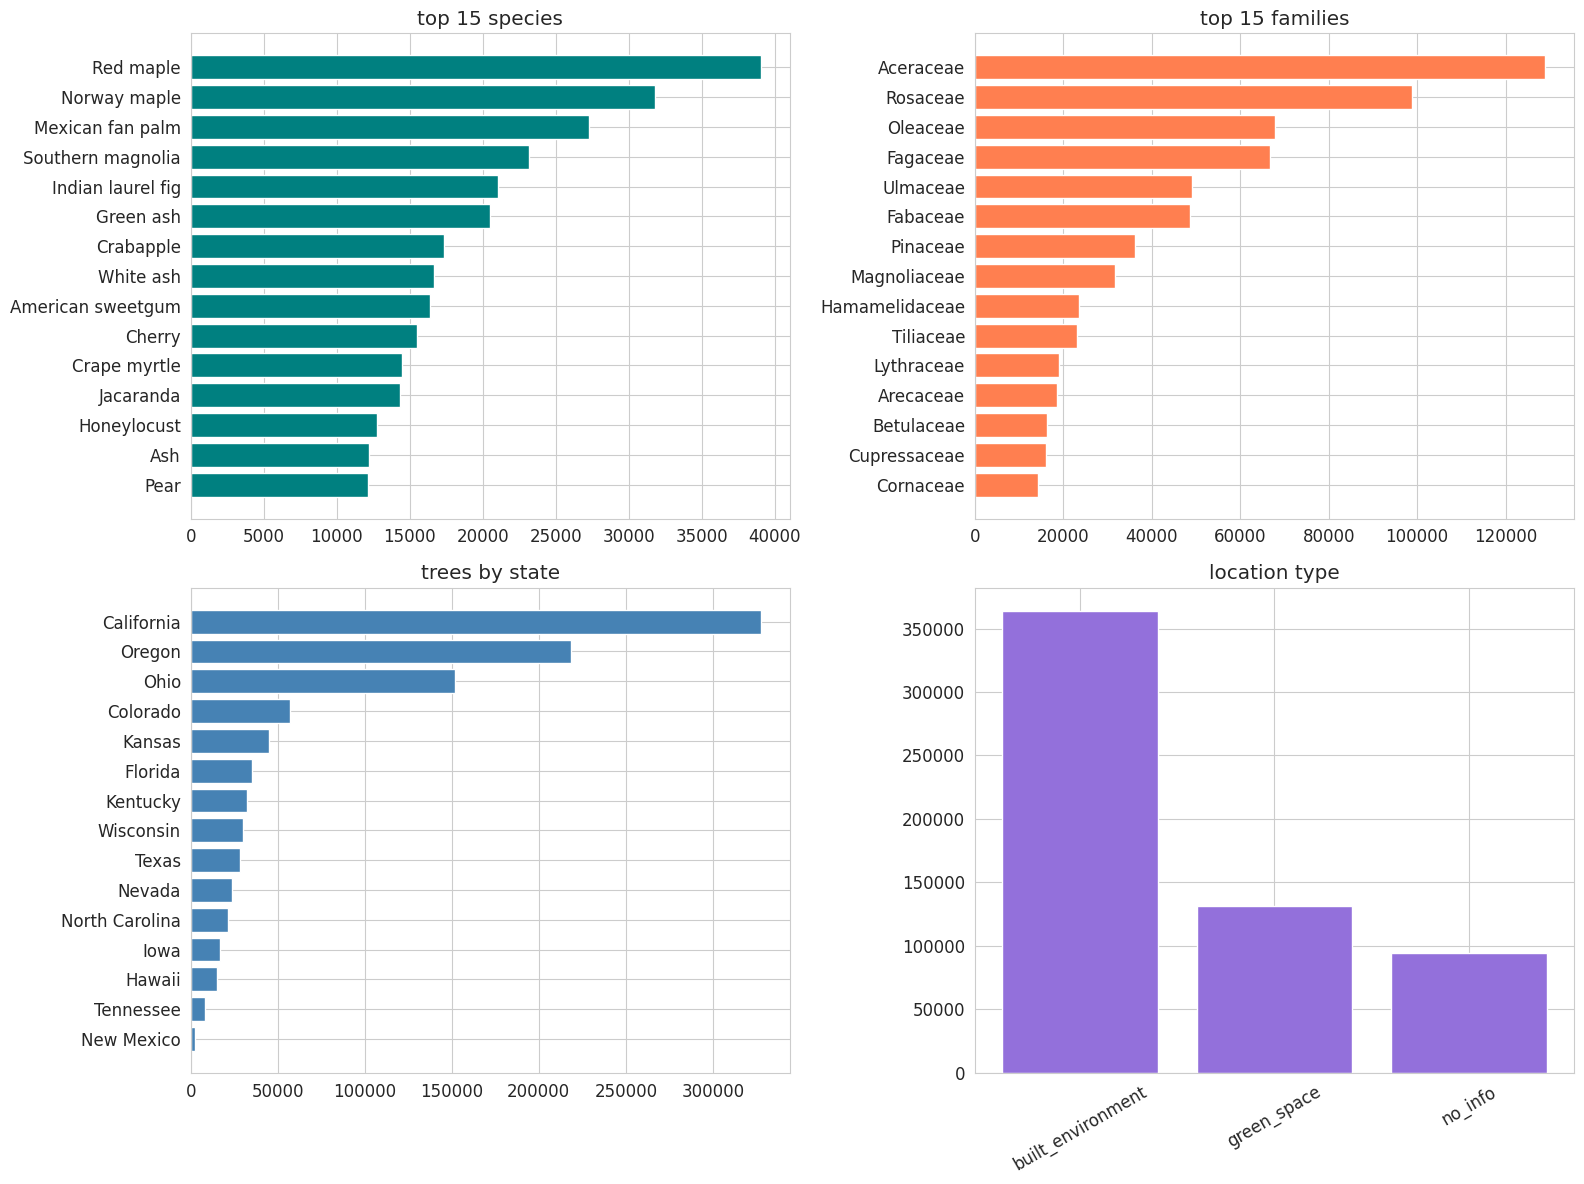

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(16, 12))

t_sp = df['common_name'].value_counts().head(15)
ax[0,0].barh(t_sp.index[::-1], t_sp.values[::-1], color='teal')
ax[0,0].set_title('top 15 species')

t_fam = df['Family'].value_counts().head(15)
ax[0,1].barh(t_fam.index[::-1], t_fam.values[::-1], color='coral')
ax[0,1].set_title('top 15 families')

st_c = df['state'].value_counts()
ax[1,0].barh(st_c.index[::-1], st_c.values[::-1], color='steelblue')
ax[1,0].set_title('trees by state')

loc_c = df['location_type'].value_counts()
ax[1,1].bar(loc_c.index, loc_c.values, color='mediumpurple')
ax[1,1].set_title('location type')
ax[1,1].tick_params(axis='x', rotation=30)

plt.tight_layout()
print('unique species:', df['common_name'].nunique())
print('unique families:', df['Family'].nunique())
print('unique cities:', df['city'].nunique())
print('unique states:', df['state'].nunique())

California, Oregon, and Ohio dominate the dataset. There are 500+
unique species - we will target-encode them rather than one-hot
encoding. Many rows have missing `Family` and `location_type`
values.

### 3.3 Correlation matrix

Soil properties at different depths (0-5, 5-15, 15-30 cm) are expected
to be highly correlated. We check this to decide which layers to
keep.

pairs with r > 0.95: 26
soil_sand_0_5 with soil_sand_5_15 0.999
soil_silt_0_5 with soil_silt_5_15 0.998
soil_sand_5_15 with soil_sand_15_30 0.998
soil_phh2o_0_5 with soil_phh2o_5_15 0.998
soil_phh2o_5_15 with soil_phh2o_15_30 0.997
soil_sand_0_5 with soil_sand_15_30 0.997
soil_wv0033_0_5 with soil_wv0033_5_15 0.995
soil_phh2o_0_5 with soil_phh2o_15_30 0.995
soil_silt_5_15 with soil_silt_15_30 0.994
soil_wv0010_0_5 with soil_wv0010_5_15 0.994


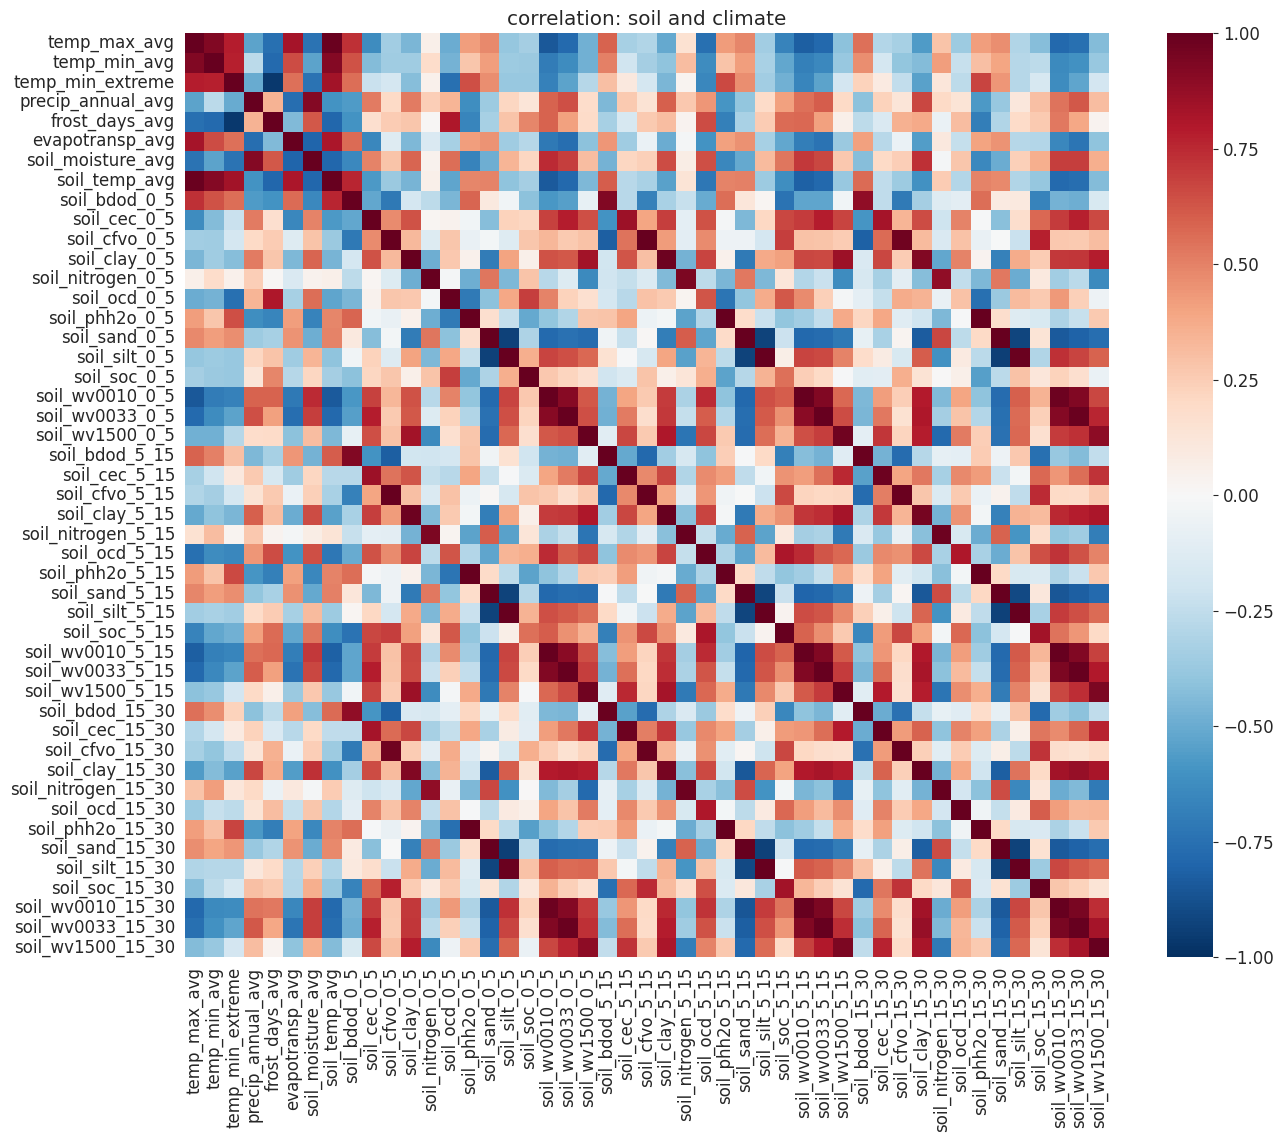

In [11]:
sc_cols = [c for c in df.columns if c.startswith(('soil_', 'temp_', 'precip_', 'frost_', 'evapotransp_'))]
c_mat = df[sc_cols].corr()

plt.figure(figsize=(15, 12))
sns.heatmap(c_mat, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True)
plt.title('correlation: soil and climate')

high = []
cols = c_mat.columns
for i in range(len(cols)):
  for j in range(i + 1, len(cols)):
    r_val = c_mat.iloc[i, j]
    if abs(r_val) > 0.95:
      high.append((cols[i], cols[j], r_val))

print('pairs with r > 0.95:', len(high))
high_s = sorted(high, key=lambda x: abs(x[2]), reverse=True)
for f1, f2, r in high_s[:10]:
  print(f1, 'with', f2, round(r, 3))

As expected, soil properties at different depths are nearly identical
(r > 0.95). We keep only the 0-5 cm layer and drop the deeper ones to
reduce multicollinearity. Some climate variables are also strongly
correlated (e.g. soil temperature and air temperature).

### 3.4 State-species mortality heatmap

The most actionable view: mortality rate for each (state, species)
pair. Red cells signal combinations where a species reliably dies - an
explicit "do not plant" signal for urban foresters. Empty cells are
combinations absent from the data.

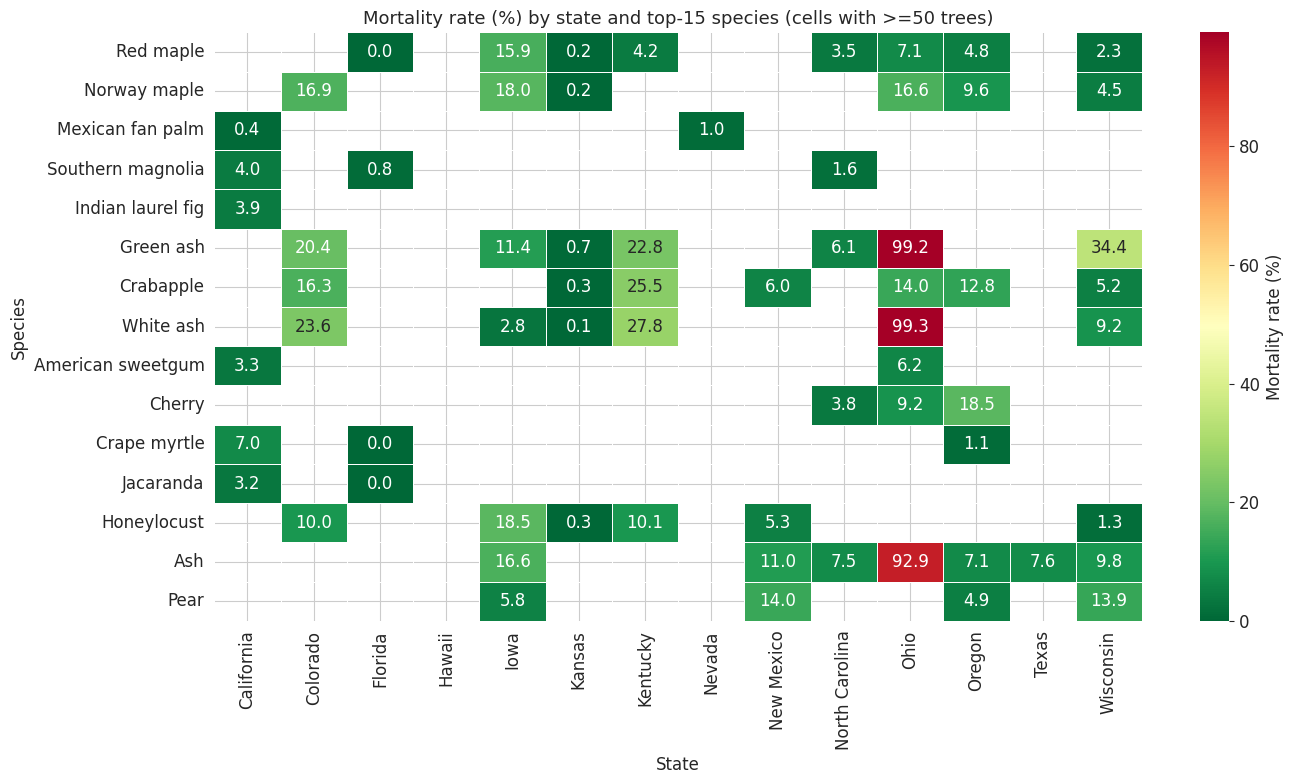

Worst (species, state) pairs:
    species     state  mortality_pct
  White ash      Ohio          99.25
  Green ash      Ohio          99.15
        Ash      Ohio          92.86
  Green ash Wisconsin          34.44
  White ash  Kentucky          27.79
  Crabapple  Kentucky          25.49
  White ash  Colorado          23.59
  Green ash  Kentucky          22.83
  Green ash  Colorado          20.44
Honeylocust      Iowa          18.52


In [12]:
top_species_15 = df['common_name'].value_counts().head(15).index.tolist()

pivot_count = df[df['common_name'].isin(top_species_15)].pivot_table(
    index='common_name', columns='state',
    values='survival_label', aggfunc='count', fill_value=0,
)

pivot_mort = df[df['common_name'].isin(top_species_15)].pivot_table(
    index='common_name', columns='state',
    values='survival_label', aggfunc=lambda x: (1 - x.mean()) * 100,
)

pivot_mort = pivot_mort.mask(pivot_count < 50)

pivot_mort = pivot_mort.loc[top_species_15]

plt.figure(figsize=(14, 8))
sns.heatmap(pivot_mort, cmap='RdYlGn_r', annot=True, fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Mortality rate (%)'},
            vmin=0, vmax=pivot_mort.max().max())
plt.title('Mortality rate (%) by state and top-15 species (cells with >=50 trees)',
          fontsize=13)
plt.xlabel('State')
plt.ylabel('Species')
plt.tight_layout()
plt.show()

print('Worst (species, state) pairs:')
worst_pairs = (pivot_mort.stack()
               .sort_values(ascending=False)
               .head(10)
               .reset_index())
worst_pairs.columns = ['species', 'state', 'mortality_pct']
print(worst_pairs.round(2).to_string(index=False))

The heatmap exposes concrete business recommendations: specific
(species, state) combinations with unusually high mortality. These are
direct "do not plant" signals that a predictive model can formalize
across the full feature space.

## 4. Data preprocessing

### 4.1 Feature selection and cleaning

We drop features that cause data leakage or are redundant:
- `condition` - directly encodes the target
- `sci_name_clean` - redundant with `common_name`
- `diameter_breast_height_binned_CM`, `height_binned_M` - binned
  versions of numeric columns we already have
- `overhead_utility` - 92% missing
- `city` - too many unique values; we keep `state` instead
- Soil features at depths 5-15 and 15-30 cm - nearly identical to the
  0-5 cm layer

In [13]:
df.columns

Index(['common_name', 'sci_name_clean', 'Family', 'city', 'state',
       'location_type', 'overhead_utility', 'diameter_breast_height_CM',
       'diameter_breast_height_binned_CM', 'height_M', 'height_binned_M',
       'native', 'condition', 'survival_label', 'temp_max_avg', 'temp_min_avg',
       'temp_min_extreme', 'precip_annual_avg', 'frost_days_avg',
       'evapotransp_avg', 'soil_moisture_avg', 'soil_temp_avg',
       'soil_bdod_0_5', 'soil_cec_0_5', 'soil_cfvo_0_5', 'soil_clay_0_5',
       'soil_nitrogen_0_5', 'soil_ocd_0_5', 'soil_phh2o_0_5', 'soil_sand_0_5',
       'soil_silt_0_5', 'soil_soc_0_5', 'soil_wv0010_0_5', 'soil_wv0033_0_5',
       'soil_wv1500_0_5', 'soil_bdod_5_15', 'soil_cec_5_15', 'soil_cfvo_5_15',
       'soil_clay_5_15', 'soil_nitrogen_5_15', 'soil_ocd_5_15',
       'soil_phh2o_5_15', 'soil_sand_5_15', 'soil_silt_5_15', 'soil_soc_5_15',
       'soil_wv0010_5_15', 'soil_wv0033_5_15', 'soil_wv1500_5_15',
       'soil_bdod_15_30', 'soil_cec_15_30', 'soil_cfvo_1

In [14]:
df.isna().sum()

,0
common_name,6705
sci_name_clean,41171
Family,255353
city,461
state,0
...,...
soil_soc_15_30,0
soil_wv0010_15_30,0
soil_wv0033_15_30,0
soil_wv1500_15_30,0


Let's check if the depth data is almost identical.

In [15]:
s0 = sorted([c for c in df.columns if c.endswith('_0_5')])
s1 = sorted([c for c in df.columns if c.endswith('_5_15')])
s2 = sorted([c for c in df.columns if c.endswith('_15_30')])

if len(s0) == len(s1):
  res = []
  for i in range(len(s0)):
    v = df[s0[i]].corr(df[s1[i]])
    name = s0[i][:-4]
    res.append([name, v])

  df_res = pd.DataFrame(res, columns=['feat', 'corr'])
  print(df_res)

             feat      corr
0       soil_bdod  0.926907
1        soil_cec  0.856381
2       soil_cfvo  0.993558
3       soil_clay  0.980906
4   soil_nitrogen  0.942295
5        soil_ocd  0.630095
6      soil_phh2o  0.997864
7       soil_sand  0.998541
8       soil_silt  0.998169
9        soil_soc  0.554206
10    soil_wv0010  0.994010
11    soil_wv0033  0.995398
12    soil_wv1500  0.973679


Yes, they are very similar, so we leave 0-5 cm as representative of the entire soil.

In [16]:
bad = ['condition', 'diameter_breast_height_binned_CM','height_binned_M',
  'overhead_utility','city']

deep = [c for c in df.columns if c.endswith(('_5_15', '_15_30'))]
bad = bad + deep
df_cl = df.drop(columns=bad)

print('dropped count:', len(bad))
print('remains:', df_cl.shape[1])
df_cl.columns.tolist()

dropped count: 31
remains: 31


['common_name',
 'sci_name_clean',
 'Family',
 'state',
 'location_type',
 'diameter_breast_height_CM',
 'height_M',
 'native',
 'survival_label',
 'temp_max_avg',
 'temp_min_avg',
 'temp_min_extreme',
 'precip_annual_avg',
 'frost_days_avg',
 'evapotransp_avg',
 'soil_moisture_avg',
 'soil_temp_avg',
 'soil_bdod_0_5',
 'soil_cec_0_5',
 'soil_cfvo_0_5',
 'soil_clay_0_5',
 'soil_nitrogen_0_5',
 'soil_ocd_0_5',
 'soil_phh2o_0_5',
 'soil_sand_0_5',
 'soil_silt_0_5',
 'soil_soc_0_5',
 'soil_wv0010_0_5',
 'soil_wv0033_0_5',
 'soil_wv1500_0_5',
 'themes']

### 4.2 Subsampling and train/validation split

With ~1M rows the full dataset is large, so in sample mode we take a
stratified subsample for faster experiments. We split 80/20 with
stratification on the target to preserve class proportions.

In [17]:
from sklearn.model_selection import train_test_split
if MAX_TRAIN_ROWS  is not None and len(df_cl) > MAX_TRAIN_ROWS :
  df_s, _ = train_test_split(
    df_cl,
    train_size=MAX_TRAIN_ROWS ,
    stratify=df_cl['survival_label'],
    random_state=RANDOM_STATE)
  print('subsampled:', len(df_cl), 'to', len(df_s))
else:
  df_s = df_cl
  print('using full data:', len(df_s))

df_tr, df_v = train_test_split(
  df_s,
  test_size=0.2,
  stratify=df_s['survival_label'],
  random_state=RANDOM_STATE)

print('train size:', len(df_tr))
print('val size:', len(df_v))
tr_rate = df_tr['survival_label'].mean()
v_rate = df_v['survival_label'].mean()
print('train rate:', round(tr_rate, 4))
print('val rate:', round(v_rate, 4))

subsampled: 1013701 to 200000
train size: 160000
val size: 40000
train rate: 0.9065
val rate: 0.9065


### 4.3 Encoding, imputation, and scaling

All transformations are fitted on the training set only to prevent data
leakage:

1. **Target encoding** for high-cardinality categoricals
   (`common_name`, `Family`) - smoothed with Bayesian shrinkage toward
   the global mean
2. **One-hot encoding** for low-cardinality categoricals (`state`,
   `location_type`, `native`)
3. **Median imputation** for missing numeric values
4. **StandardScaler** on all features

In [18]:
from sklearn.preprocessing import StandardScaler

y_tr = df_tr['survival_label'].values
y_v = df_v['survival_label'].values
te_cols = ['common_name', 'Family']
ohe_cols = ['state', 'location_type', 'native']
num_cols = [
  c for c in df_tr.columns
  if c not in te_cols + ohe_cols + ['survival_label']
  and df_tr[c].dtype in ['float64', 'int64']]
smooth = 50
avg = y_tr.mean()
maps = {}

for c in te_cols:
  st = df_tr.groupby(c)['survival_label'].agg(['mean', 'count'])
  val = (st['count']*st['mean']+smooth*avg)/(st['count']+smooth)
  maps[c] = val.to_dict()
for c in te_cols:
  df_tr[c + '_e'] = df_tr[c].map(maps[c]).fillna(avg)
  df_v[c + '_e'] = df_v[c].map(maps[c]).fillna(avg)
for c in ohe_cols:
  df_tr[c] = df_tr[c].fillna('unk').astype(str)
  df_v[c] = df_v[c].fillna('unk').astype(str)

ohe_tr = pd.get_dummies(df_tr[ohe_cols], drop_first=True)
ohe_v = pd.get_dummies(df_v[ohe_cols], drop_first=True)
ohe_v = ohe_v.reindex(columns=ohe_tr.columns, fill_value=0)
te_new = [c + '_e' for c in te_cols]
FEATURE_NAMES = num_cols + te_new + ohe_tr.columns.tolist()
X_tr = pd.concat([
  df_tr[num_cols + te_new].reset_index(drop=True),
  ohe_tr.reset_index(drop=True)], axis=1)

X_v = pd.concat([
  df_v[num_cols + te_new].reset_index(drop=True),
  ohe_v.reset_index(drop=True)], axis=1)
med = X_tr[num_cols].median()
X_tr[num_cols] = X_tr[num_cols].fillna(med)
X_v[num_cols] = X_v[num_cols].fillna(med)
X_tr = X_tr.replace([np.inf, -np.inf], np.nan).fillna(0)
X_v = X_v.replace([np.inf, -np.inf], np.nan).fillna(0)
sc = StandardScaler()
X_tr_sc = sc.fit_transform(X_tr)
X_v_sc = sc.transform(X_v)

print('features:', X_tr_sc.shape[1])
print('train shape:', X_tr_sc.shape)
print('val shape:', X_v_sc.shape)

features: 44
train shape: (160000, 44)
val shape: (40000, 44)


### 4.4 Dimensionality reduction with PCA

PCA decorrelates features and reduces dimensionality. We keep 95% of
the variance. We will use PCA features for distance-based models (KNN,
Logistic Regression) and the original scaled features for tree-based
models.

original: 44
pca comps: 18


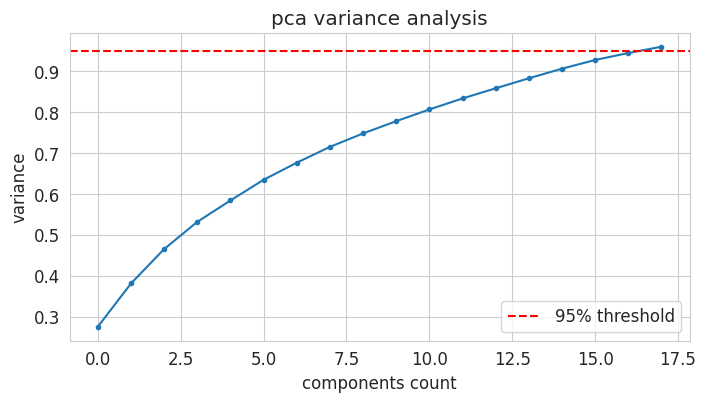

In [19]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_tr_p = pca.fit_transform(X_tr_sc)
X_v_p = pca.transform(X_v_sc)

print('original:', X_tr_sc.shape[1])
print('pca comps:', X_tr_p.shape[1])
plt.figure(figsize=(8, 4))
v_sum = np.cumsum(pca.explained_variance_ratio_)
plt.plot(v_sum, marker='o', markersize=3)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% threshold')
plt.xlabel('components count')
plt.ylabel('variance')
plt.title('pca variance analysis')
plt.legend()
plt.grid(True)

PCA compresses the feature space substantially. We use PCA features for
Logistic Regression and KNN (both benefit from decorrelated, lower-
dimensional inputs), and the original scaled features for Random Forest
and XGBoost (tree-based models handle many correlated features well on
their own).

## 5. Model training

We train 4 models of fundamentally different nature and compare them:

| # | Model | Type |
|---|---|---|
| 1 | Logistic Regression | Linear model |
| 2 | K-Nearest Neighbors | Instance-based |
| 3 | Random Forest | Bagging ensemble |
| 4 | XGBoost | Gradient boosting |

All models use `class_weight='balanced'` (or equivalent) to handle the
55:1 class imbalance. We report F1, precision, and recall **for the
minority class (dead)**, not the majority class - a dummy classifier
that always predicts "alive" would score F1=0.991 for the alive class,
which is meaningless. AUC-ROC is class-agnostic and reliable here.

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, RocCurveDisplay)

results = {}

def evaluate_model(name, model, X_tr, y_tr, X_v, y_v):
    print(f'Training: {name}')

    start = time.time()
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_v)
    y_proba = (model.predict_proba(X_v)[:, 1]
               if hasattr(model, 'predict_proba') else None)
    elapsed = time.time() - start
    metrics = {
        'model': name,
        'auc_roc': roc_auc_score(y_v, y_proba) if y_proba is not None else None,
        'f1_dead': f1_score(y_v, y_pred, pos_label=0),
        'precision_dead': precision_score(y_v, y_pred, pos_label=0, zero_division=0),
        'recall_dead': recall_score(y_v, y_pred, pos_label=0),
        'time_sec': round(elapsed, 1),
    }

    for k in ['auc_roc', 'f1_dead', 'precision_dead', 'recall_dead']:
        v = metrics[k]
        print(f'{k:16s} {v:.4f}' if v is not None else f'{k:16s} N/A')
    print(f'{"time":16s} {elapsed:.1f}s')
    print(f'\n{classification_report(y_v, y_pred, target_names=["dead", "alive"])}')

    results[name] = {
        'model': model, 'metrics': metrics,
        'y_proba': y_proba, 'y_pred': y_pred,
    }
    return metrics

### 5.1 Logistic regression

A linear baseline. We use PCA features since logistic regression
benefits from decorrelated, lower-dimensional inputs.

In [39]:
lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1,)
evaluate_model('Logistic Regression', lr,X_tr_p, y_tr, X_v_p, y_v)

Training: Logistic Regression
auc_roc          0.7701
f1_dead          0.3263
precision_dead   0.2229
recall_dead      0.6083
time             3.3s

              precision    recall  f1-score   support

        dead       0.22      0.61      0.33      3740
       alive       0.95      0.78      0.86     36260

    accuracy                           0.77     40000
   macro avg       0.59      0.69      0.59     40000
weighted avg       0.88      0.77      0.81     40000



{'model': 'Logistic Regression',
 'auc_roc': np.float64(0.7700984902560533),
 'f1_dead': 0.3262584253549405,
 'precision_dead': 0.22290809327846364,
 'recall_dead': 0.6082887700534759,
 'time_sec': 3.3}

### 5.2 K-nearest neighbors

KNN is expensive on large datasets, so we subsample the training set.
We use PCA features to reduce the curse of dimensionality.

In [40]:
if KNN_MAX_SAMPLES and len(X_tr_p) > KNN_MAX_SAMPLES:
  idx = np.random.choice(len(X_tr_p), KNN_MAX_SAMPLES, replace=False)
  x_k, y_k = X_tr_p[idx], y_tr[idx]
  print('knn: subsampled to', KNN_MAX_SAMPLES)
else:
  x_k, y_k = X_tr_p, y_tr

knn = KNeighborsClassifier(
  n_neighbors=KNN_NEIGHBORS,
  weights='distance',
  n_jobs=-1)

evaluate_model('knn', knn, x_k, y_k, X_v_p, y_v)

knn: subsampled to 30000
Training: knn
auc_roc          0.7186
f1_dead          0.3963
precision_dead   0.5788
recall_dead      0.3013
time             22.1s

              precision    recall  f1-score   support

        dead       0.58      0.30      0.40      3740
       alive       0.93      0.98      0.95     36260

    accuracy                           0.91     40000
   macro avg       0.76      0.64      0.68     40000
weighted avg       0.90      0.91      0.90     40000



{'model': 'knn',
 'auc_roc': np.float64(0.7186483905601553),
 'f1_dead': 0.3963425356075259,
 'precision_dead': 0.578839239856189,
 'recall_dead': 0.3013368983957219,
 'time_sec': 22.1}

### 5.3 Random forest

Tree-based models handle high-dimensional data well. We use all scaled
features (not PCA) so the forest can pick the most informative
splits.

In [41]:
rf = RandomForestClassifier(
    n_estimators=RF_ESTIMATORS,
    max_depth=20,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1,)
evaluate_model('Random Forest', rf, X_tr_sc, y_tr, X_v_sc, y_v)

Training: Random Forest
auc_roc          0.7762
f1_dead          0.3789
precision_dead   0.2862
recall_dead      0.5604
time             19.9s

              precision    recall  f1-score   support

        dead       0.29      0.56      0.38      3740
       alive       0.95      0.86      0.90     36260

    accuracy                           0.83     40000
   macro avg       0.62      0.71      0.64     40000
weighted avg       0.89      0.83      0.85     40000



{'model': 'Random Forest',
 'auc_roc': np.float64(0.7761683408006937),
 'f1_dead': 0.37888647866955893,
 'precision_dead': 0.2861824139814309,
 'recall_dead': 0.560427807486631,
 'time_sec': 19.9}

### 5.4 XGBoost

Gradient boosting typically achieves the best performance on tabular
data. We set `scale_pos_weight` to handle class imbalance (downweight
the majority "alive" class).

In [42]:
from xgboost import XGBClassifier

w = (y_tr == 0).sum()/(y_tr == 1).sum()

xgb = XGBClassifier(
    n_estimators=XGB_ESTIMATORS,
    max_depth=8,
    learning_rate=0.1,
    scale_pos_weight=w,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric='logloss',
    verbosity=0,)
evaluate_model('XGBoost', xgb, X_tr_sc, y_tr, X_v_sc, y_v)

Training: XGBoost
auc_roc          0.8135
f1_dead          0.3597
precision_dead   0.2453
recall_dead      0.6741
time             2.9s

              precision    recall  f1-score   support

        dead       0.25      0.67      0.36      3740
       alive       0.96      0.79      0.86     36260

    accuracy                           0.78     40000
   macro avg       0.60      0.73      0.61     40000
weighted avg       0.89      0.78      0.82     40000



{'model': 'XGBoost',
 'auc_roc': np.float64(0.8135478355961548),
 'f1_dead': 0.3597317351598174,
 'precision_dead': 0.24532892175943946,
 'recall_dead': 0.6740641711229947,
 'time_sec': 2.9}

## 6. Model comparison

We aggregate metrics for all models and compare them visually.

In [25]:
metrics_df = pd.DataFrame(
    [r['metrics'] for r in results.values()]).set_index('model')
metrics_df = metrics_df.sort_values('auc_roc', ascending=False)
print(metrics_df.round(4).to_string())

                     auc_roc  f1_dead  precision_dead  recall_dead  time_sec
model                                                                       
XGBoost               0.8135   0.3597          0.2453       0.6741       2.9
Random Forest         0.7762   0.3789          0.2862       0.5604      17.4
Logistic Regression   0.7701   0.3263          0.2229       0.6083       3.5
knn                   0.7199   0.3986          0.5674       0.3072      20.2


Bar charts make it easier to see which model dominates on each
metric.

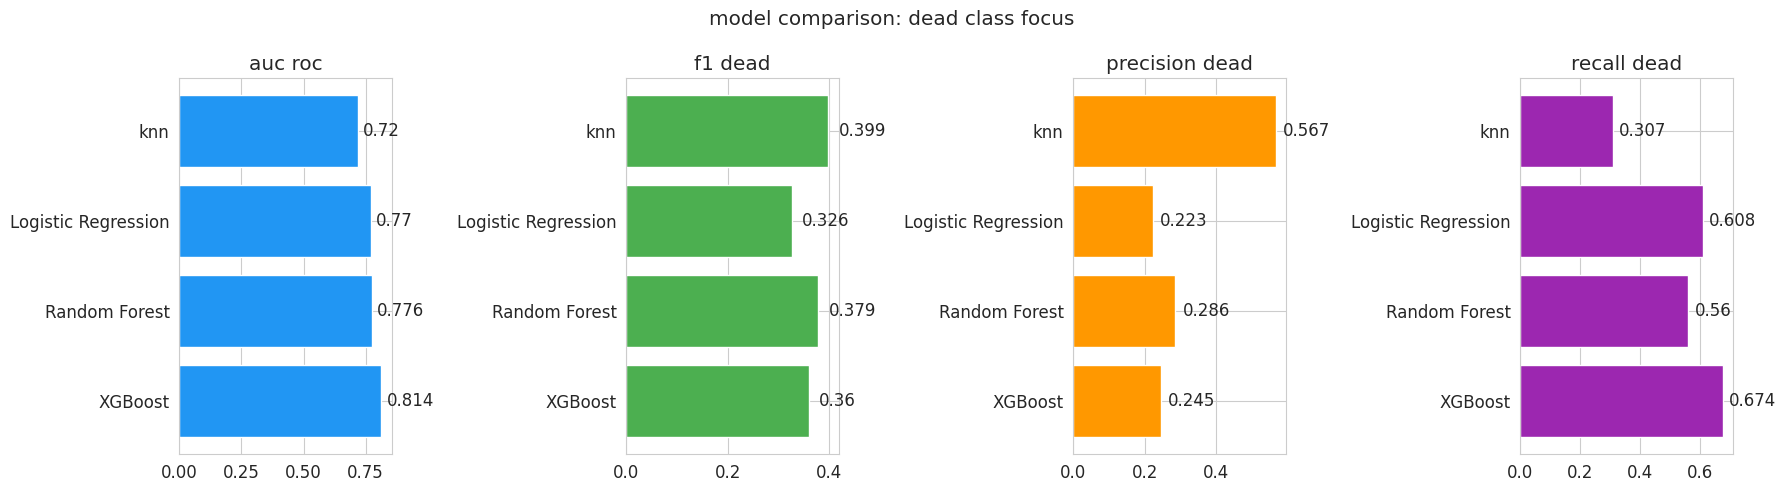

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
m_names = ['auc_roc', 'f1_dead', 'precision_dead', 'recall_dead']
clrs = ['#2196f3', '#4caf50', '#ff9800', '#9c27b0']
for i, m in enumerate(m_names):
  vals = metrics_df[m].values
  models = metrics_df.index
  b = axes[i].barh(models, vals, color=clrs[i])
  axes[i].set_title(m.replace('_', ' '))
  for bar, v in zip(b, vals):
    axes[i].text(v + 0.02, bar.get_y() + bar.get_height()/2, round(v, 3), va='center')

plt.suptitle('model comparison: dead class focus')
plt.tight_layout()

ROC curves show the trade-off between true positive rate and false
positive rate at all thresholds.

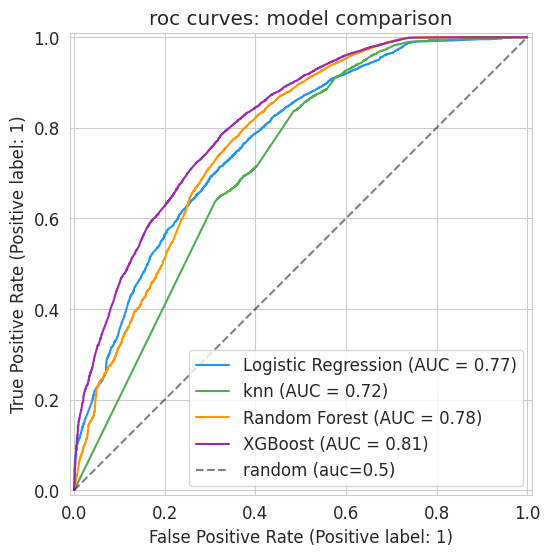

In [27]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))
clrs = ['#2196f3', '#4caf50', '#ff9800', '#9c27b0']
for i, (name, r) in enumerate(results.items()):
  if r['y_proba'] is not None:
    RocCurveDisplay.from_predictions(
      y_v, r['y_proba'],name=name,ax=ax, color=clrs[i%len(clrs)])
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='random (auc=0.5)')
ax.set_title('roc curves: model comparison')
ax.legend(loc='lower right')

Confusion matrices show absolute counts of correct and incorrect
predictions.

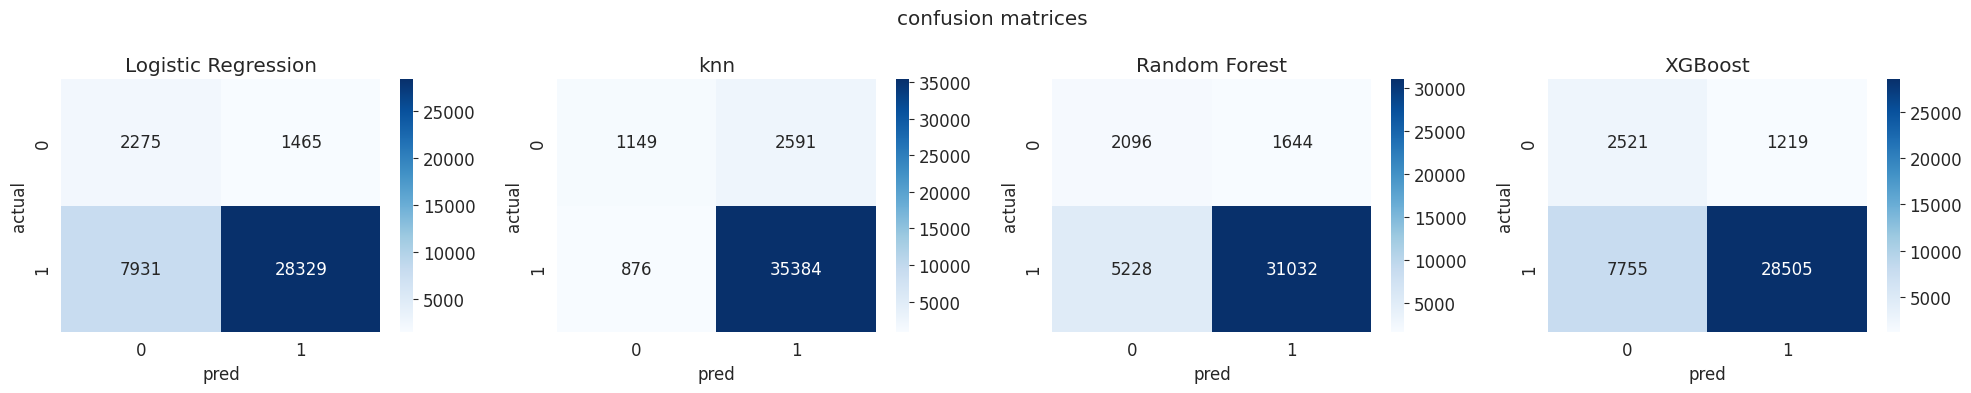

In [28]:
num = len(results)
fig, ax = plt.subplots(1, num, figsize=(5 * num, 4))

if num == 1:
  ax = [ax]
for i, (name, r) in enumerate(results.items()):
  cm = confusion_matrix(y_v, r['y_pred'])
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[i])
  ax[i].set_title(name)
  ax[i].set_xlabel('pred')
  ax[i].set_ylabel('actual')

plt.suptitle('confusion matrices')
plt.tight_layout()

## 7. Feature importance

We look at which features the tree-based models found most useful for
predicting survival.

Text(0.5, 1.0, 'top 20: xgboost')

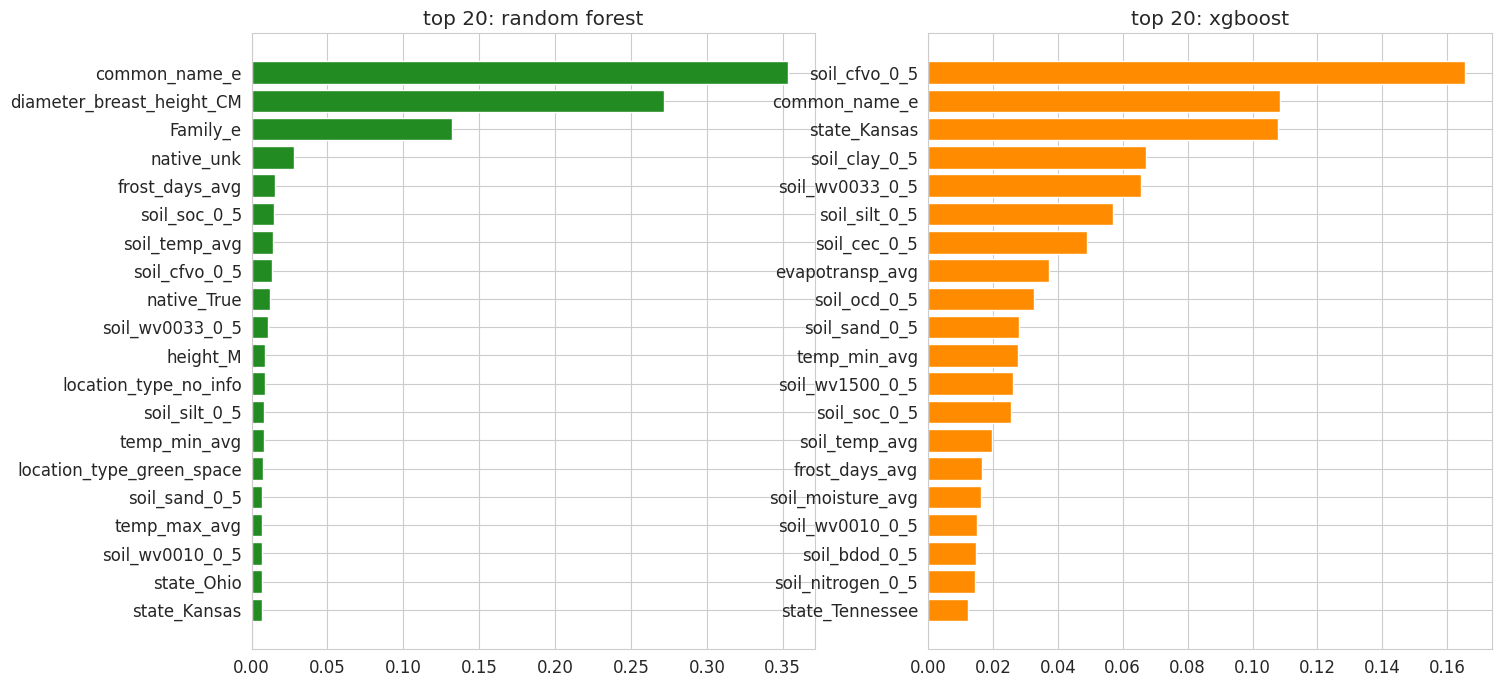

In [29]:
results['Random Forest']['model'].fit(X_tr_sc, y_tr)
results['XGBoost']['model'].fit(X_tr_sc, y_tr)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
m_rf = results['Random Forest']['model']
df_rf = pd.DataFrame({'f': FEATURE_NAMES,'imp': m_rf.feature_importances_})
df_rf = df_rf.sort_values('imp', ascending=False).head(20)

ax[0].barh(df_rf['f'][::-1], df_rf['imp'][::-1], color='forestgreen')
ax[0].set_title('top 20: random forest')
m_xgb = results['XGBoost']['model']
df_xgb = pd.DataFrame({'f': FEATURE_NAMES,'imp': m_xgb.feature_importances_})
df_xgb = df_xgb.sort_values('imp', ascending=False).head(20)

ax[1].barh(df_xgb['f'][::-1], df_xgb['imp'][::-1], color='darkorange')
ax[1].set_title('top 20: xgboost')

### 7.1 SHAP analysis

SHAP (SHapley Additive exPlanations) provides a principled,
game-theory-based feature importance. It shows not just which features
matter, but how each feature value pushes the prediction toward
survival or death.

Text(0.5, 1.0, 'shap analysis: xgboost')

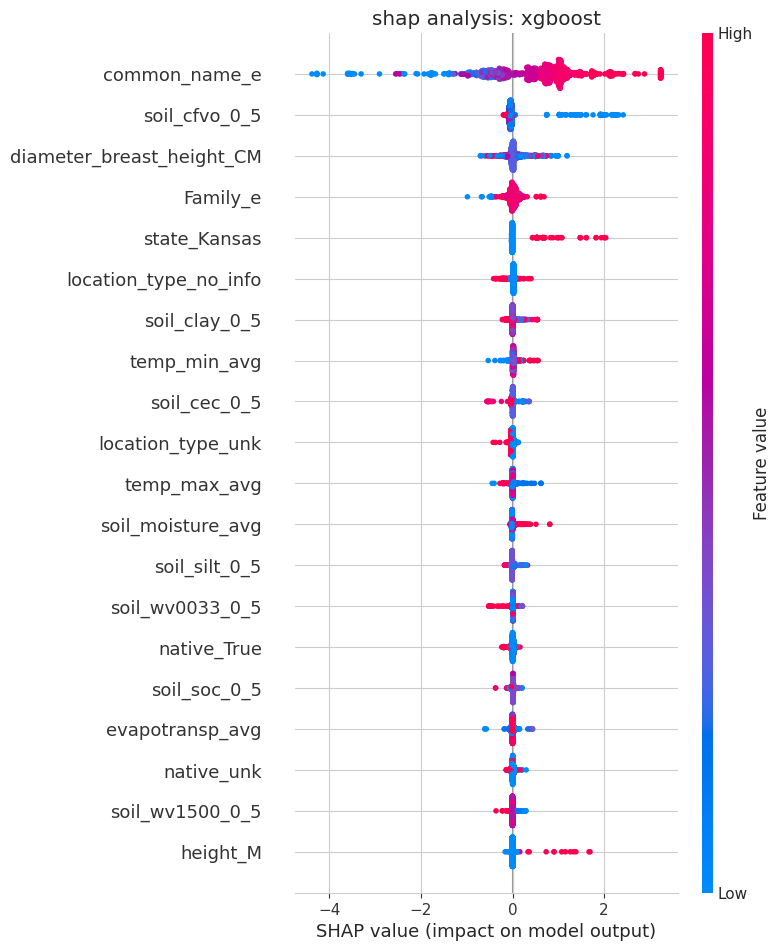

In [30]:
import shap
m_xgb = results['XGBoost']['model']
ex = shap.TreeExplainer(results['XGBoost']['model'])
sh_val = ex.shap_values(X_v_sc[:1000])
idx = np.random.choice(len(X_v_sc), size=min(1000, len(X_v_sc)), replace=False)
x_sh = X_v_sc[idx]

sh_val = ex.shap_values(x_sh)
plt.figure(figsize=(10, 8))
shap.summary_plot(sh_val, x_sh, feature_names=FEATURE_NAMES, max_display=20, show=False)
plt.title('shap analysis: xgboost')

SHAP dependence plots for the top 4 features show the non-linear
relationship between feature values and their impact on the
prediction.

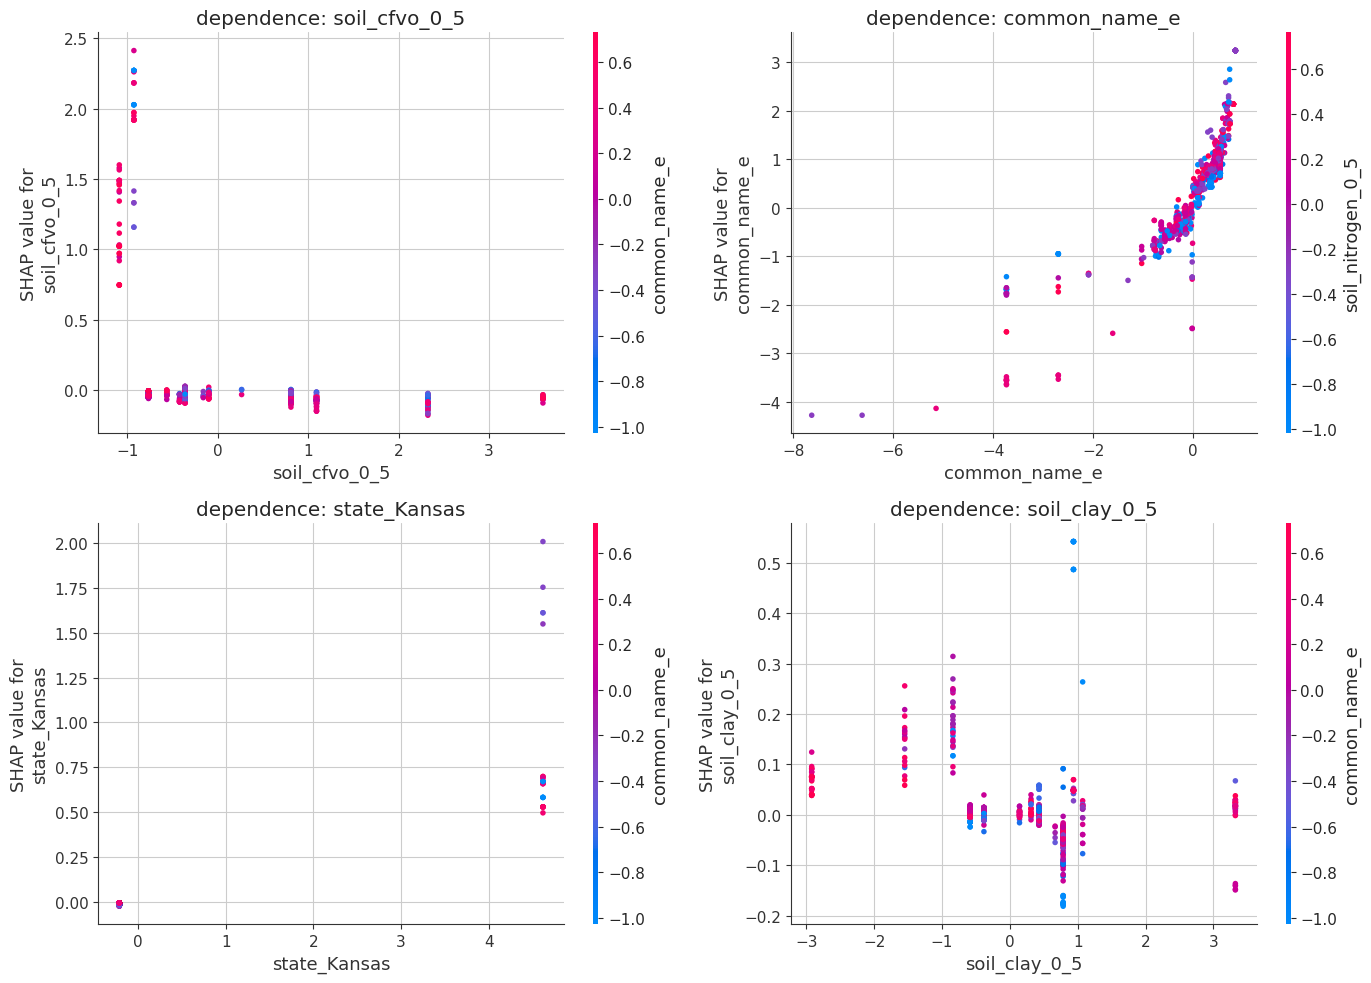

In [31]:
m_xgb = results['XGBoost']['model']
m_xgb.fit(X_tr_sc, y_tr)

xgb_imp = pd.DataFrame({
  'feature': FEATURE_NAMES,
  'importance': m_xgb.feature_importances_
}).sort_values('importance', ascending=False)
ex = shap.TreeExplainer(m_xgb)
idx = np.random.choice(len(X_v_sc), size=min(1000, len(X_v_sc)), replace=False)
x_sh = X_v_sc[idx]
sh_val = ex.shap_values(x_sh)
top_4 = xgb_imp.head(4)['feature'].tolist()
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax = ax.flatten()

for i, f in enumerate(top_4):
  f_idx = FEATURE_NAMES.index(f)
  shap.dependence_plot(f_idx, sh_val, x_sh, feature_names=FEATURE_NAMES, ax=ax[i], show=False)
  ax[i].set_title('dependence: ' + f)
plt.tight_layout()

# Garden style tree recommendation

Recommnder system that suggests tree species for user input (free-text description), which includes garden style, location and other parameters

Limitations
- Small garden style array

In [32]:
import re
res_set = set()
for i in df['themes'].dropna():
    txt = re.sub(r"[\[\];]", ',', str(i))
    ch = txt.split(',')
    for p in ch:
        p = p.strip().strip("'").strip('"')
        if p != '':
            res_set.add(p)

res = sorted(list(res_set))
print('all garden styles')
print(res)

all garden styles
['Asian Garden', 'Butterfly Garden', "Children's Garden", 'Cottage Garden', 'Cutting Garden', 'Drought Tolerant Garden', 'Edible Garden', 'English Garden', 'Fairy Garden', 'Garden for the Blind', 'Native Garden', 'Nighttime Garden', 'Pollinator Garden', 'Rain Garden', 'Rock Garden', 'Shade Garden', 'Water Garden', 'Winter Garden']


['Asian Garden', 'Butterfly Garden', "Children's Garden", 'Cottage Garden', 'Cutting Garden', 'Drought Tolerant Garden', 'Edible Garden', 'English Garden', 'Fairy Garden', 'Garden for the Blind', 'Native Garden', 'Nighttime Garden', 'Pollinator Garden', 'Rain Garden', 'Rock Garden', 'Shade Garden', 'Water Garden', 'Winter Garden']


In [33]:
def prep_data(env, species):
  t = pd.DataFrame([env] * len(species))
  t['common_name'] = species
  info = df[['common_name', 'Family', 'native']].drop_duplicates('common_name')
  t = t.merge(info, on='common_name', how='left', suffixes=('', '_db'))

  if 'native_db' in t.columns:
    t['native'] = t['native_db']
  for c in ohe_cols:
    if c not in t.columns:
      t[c] = 'unk'
  for c in te_cols:
    t[c + '_e'] = t[c].map(maps[c]).fillna(avg)
  o = pd.get_dummies(t[ohe_cols]).reindex(columns=ohe_tr.columns, fill_value=0)
  X = pd.concat([t[num_cols + te_new].reset_index(drop=True), o.reset_index(drop=True)], axis=1)
  return sc.transform(X)

In [34]:
!pip install -U sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.3/571.3 kB 2.4 MB/s eta 0:00:00
  Attempting uninstall: sentence-transformers
    Found existing installation: sentence-transformers 5.4.0
    Uninstalling sentence-transformers-5.4.0:
      Successfully uninstalled sentence-transformers-5.4.0


In [35]:
from sentence_transformers import SentenceTransformer, util
import torch
import random
model = SentenceTransformer('all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (3 outputs left out)

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [36]:
unq = df['themes'].dropna().unique()
themb = model.encode(unq, convert_to_tensor=True)

def landscape_des(user_env, user_style, n=10):
  qemb = model.encode(user_style, convert_to_tensor=True)
  cosscore = util.cos_sim(qemb, themb)[0]
  bestst_id = torch.argmax(cosscore).item()
  bestst = unq[bestst_id]
  score = cosscore[bestst_id].item()
  print(f'best match styles {bestst} match {score:.2%}')
  matchednam = df_cl[df_cl['themes'] == bestst]['common_name'].unique()
  if len(matchednam) == 0:
    print('no matching styles')

  X_sc = prep_data(user_env, matchednam)
  probs = results['XGBoost']['model'].predict_proba(X_sc)[:, 1]
  res = pd.DataFrame({'tree': matchednam, 'survival_prob': probs})
  res = res.sort_values('survival_prob', ascending=False)
  fr, seen = [], set()
  for i, row in res.iterrows():
    b = row['tree'].lower().split()[-1]
    if b not in seen:
      fr.append(row)
      seen.add(b)
    if len(fr) >= n:
      break
  print(pd.DataFrame(fr))

In [37]:
tests = [{'query': 'herbs', 'env': {'state': 'CA', 'temp_max_avg': 28, 'temp_min_extreme': 5}},
    {'query': 'fast growing screening', 'env': {'state': 'TX', 'temp_max_avg': 35, 'soil_phh2o_0_5': 7.5}},
    {'query': 'thorny protective hedge', 'env': {'state': 'AZ', 'temp_max_avg': 40, 'soil_phh2o_0_5': 8.0}}]

for t in tests:
  ex_t = t['env'].copy()
  for c in num_cols:
    if c not in ex_t: ex_t[c] = med.get(c, 0)
  print()
  print(f'{t['query']} in {ex_t['state']}')
  landscape_des(ex_t, t['query'])


herbs in CA
best match styles ['Edible Garden'] match 54.74%
                 tree  survival_prob
4                 Fig       0.714854
10    Bay fig moreton       0.649336
8        Edible apple       0.646891
12      Common banana       0.607400
13      Macadamia nut       0.599208
3          Grapefruit       0.588925
9           Macadamia       0.356725
1   Sargent crabapple       0.340673

fast growing screening in TX
best match styles ['Drought Tolerant Garden'] match 25.64%
                                    tree  survival_prob
12                    Common crapemyrtle       0.894222
3                           Crepe myrtle       0.833502
13                              Silk oak       0.747108
26                               Juniper       0.722573
1                      Hardy rubber tree       0.697962
28                         Still tree be       0.662602
22                      Monterey cypress       0.599208
27  Hardy rubbertree (eucommia ulmoides)       0.599208
4           

The goal of the project is to simulate the work of a landscape designer. The project consists of two blocks, with the second building upon the results of the first. In the first block, a predictive task (survival_label) is set, where models predict a plant’s survival probability based on its characteristics and environmental conditions.

Logistic Regression captures simple linear relationships well, but is limited in accounting for complex interactions between features, such as those found in soil, where there are many features.
Decision Trees build interpretable rules, but are prone to overfitting and are less stable.

Random Forest demonstrates greater stability and better accounts for nonlinear relationships between environmental conditions and plant species, which is ideal when analyzing not only soil across different layers but also weather conditions.

CatBoost delivers the best results by working with categorical features and its ability to effectively model complex relationships without manual coding.
All models are trained on a single dataset (which describes cases of plant planting in different U.S. states and their outcomes, where the outcomes were used in the test) and are compared using metrics (F1, ROC-AUC). Each model outputs a probability (predict_proba), which is used to rank plants and select the most suitable options.
